In [1]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

project_dir = Path(
    "/content/drive/MyDrive/vendora_botsort_reid_rebuild"
)

print("Project folder exists:", project_dir.exists())

if project_dir.exists():
    print("\nAvailable files:")
    for path in sorted(project_dir.iterdir()):
        if path.is_file():
            print(f"{path.name}  ({path.stat().st_size / 1024:.1f} KB)")

Mounted at /content/drive
Project folder exists: True

Available files:
all_views_botsort_tracks.csv  (1627.4 KB)
all_views_track_quality_summary.csv  (17.9 KB)
all_views_tracks_manual_corrections.csv  (1646.2 KB)
all_views_tracks_manual_corrections_v2.csv  (1645.6 KB)
all_views_tracks_manual_corrections_v3.csv  (1645.4 KB)
all_views_tracks_manual_corrections_v4.csv  (1645.4 KB)
all_views_tracks_manual_corrections_v5.csv  (1645.4 KB)
botsort_reid.yaml  (0.2 KB)
botsort_view3_test.yaml  (0.2 KB)
candidate_identity_edges.csv  (2.3 KB)
candidate_identity_groups.csv  (0.2 KB)
candidate_identity_mapping.csv  (0.2 KB)
confirmed_duplicate_pair_lifetimes.csv  (2.4 KB)
duplicate_review_contact_sheet.jpg  (916.3 KB)
duplicate_review_decisions.csv  (2.6 KB)
duplicate_review_manifest.csv  (0.9 KB)
frame_level_duplicate_audit.csv  (91.7 KB)
global_identity_frame_collisions.csv  (5.3 KB)
global_identity_track_continuity.csv  (0.4 KB)
global_identity_validation_summary.csv  (0.2 KB)
long_track_gaps_r

In [2]:
import pandas as pd
from pathlib import Path

project_dir = Path("/content/drive/MyDrive/vendora_botsort_reid_rebuild")

# Use the latest saved correction file currently available
tracks_path = project_dir / "all_views_tracks_manual_corrections_v5.csv"
if not tracks_path.exists():
    tracks_path = project_dir / "all_views_botsort_tracks.csv"

tracks = pd.read_csv(tracks_path)

print("TRACKING DATA")
print("File:", tracks_path.name)
print("Rows:", len(tracks))
print("Columns:", tracks.columns.tolist())

print("\nVIEW SUMMARY")
summary = tracks.groupby("view_id").agg(
    detections=("frame_index", "size"),
    unique_original_tracks=("track_id", "nunique"),
    first_frame=("frame_index", "min"),
    last_frame=("frame_index", "max")
)
display(summary)

print("\nMISSING VALUES")
display(tracks.isna().sum().to_frame("missing_values"))

print("\nVIDEO CHECK")
video_candidates = [
    Path("/content/combined_cctv.mp4"),
    project_dir / "combined_cctv.mp4"
]
for path in video_candidates:
    print(f"{path}: {'FOUND' if path.exists() else 'not found'}")

print("\nZONE ANNOTATION FILES")
for path in project_dir.glob("*zone*.json"):
    print(path.name)

TRACKING DATA
File: all_views_tracks_manual_corrections_v5.csv
Rows: 11141
Columns: ['frame_index', 'timestamp_sec', 'view_id', 'track_id', 'confidence', 'x1', 'y1', 'x2', 'y2', 'foot_x', 'foot_y', 'corrected_track_id']

VIEW SUMMARY


,detections,unique_original_tracks,first_frame,last_frame
view_id,,,,
1,2186,35,0,239
2,1677,26,240,479
3,1911,27,480,719
4,2254,40,720,959
5,1453,21,960,1199
6,1660,45,1200,1439



MISSING VALUES


,missing_values
frame_index,0
timestamp_sec,0
view_id,0
track_id,0
confidence,0
x1,0
y1,0
x2,0
y2,0
foot_x,0



VIDEO CHECK
/content/combined_cctv.mp4: FOUND
/content/drive/MyDrive/vendora_botsort_reid_rebuild/combined_cctv.mp4: not found

ZONE ANNOTATION FILES


In [5]:
import json
import pandas as pd
from pathlib import Path

project_dir = Path("/content/drive/MyDrive/vendora_botsort_reid_rebuild")
tracks_path = project_dir / "all_views_tracks_manual_corrections_v5.csv"
zones_path = Path("/content/combined_cctv__2__zones.json")

with open(zones_path, "r") as f:
    zone_data = json.load(f)

tracks = pd.read_csv(tracks_path)

print("PROJECT:", zone_data.get("project"))
print("VIDEO RESOLUTION:", zone_data.get("video_resolution"))
print("FPS:", zone_data.get("fps"))
print("VIEW DURATION:", zone_data.get("view_duration_sec"), "seconds")
print("\nZONE SUMMARY")

zone_rows = []
for view in zone_data["views"]:
    view_id = int(view["view_id"])
    view_zones = view.get("zones", [])

    for zone in view_zones:
        points = zone.get("points", [])
        zone_rows.append({
            "view_id": view_id,
            "zone_name": zone.get("name"),
            "zone_type": zone.get("type"),
            "polygon_points": len(points),
            "tracking_rows_in_view": int((tracks["view_id"] == view_id).sum()),
            "start_sec": view.get("start_sec"),
            "end_sec": view.get("end_sec")
        })

zone_summary = pd.DataFrame(zone_rows)
display(zone_summary)

print("\nVIEWS PRESENT IN TRACKS:", sorted(tracks["view_id"].unique().tolist()))
print("VIEWS PRESENT IN JSON:", sorted(int(v["view_id"]) for v in zone_data["views"]))
print("TOTAL ZONES:", len(zone_rows))

PROJECT: Vendora
VIDEO RESOLUTION: {'width': 1280, 'height': 720}
FPS: 24.0
VIEW DURATION: 10.0 seconds

ZONE SUMMARY


,view_id,zone_name,zone_type,polygon_points,tracking_rows_in_view,start_sec,end_sec
0,1,zone_A,shelf,5,2186,0.0,10.0
1,1,zone_B,shelf,5,2186,0.0,10.0
2,2,zone_C,shelf,5,1677,10.0,20.0
3,2,zone_D,shelf,7,1677,10.0,20.0
4,3,zone_E,shelf,5,1911,20.0,30.0
5,4,zone_F,general,9,2254,30.0,40.0
6,5,zone_G,shelf,5,1453,40.0,50.0
7,6,zone_H,shelf,5,1660,50.0,60.0
8,6,zone_I,shelf,5,1660,50.0,60.0
9,6,zone_J,shelf,4,1660,50.0,60.0



VIEWS PRESENT IN TRACKS: [1, 2, 3, 4, 5, 6]
VIEWS PRESENT IN JSON: [1, 2, 3, 4, 5, 6]
TOTAL ZONES: 10


In [6]:
import json
import cv2
import numpy as np
import pandas as pd
from pathlib import Path

project_dir = Path("/content/drive/MyDrive/vendora_botsort_reid_rebuild")
tracks_path = project_dir / "all_views_tracks_manual_corrections_v5.csv"
zones_path = Path("/content/combined_cctv__2__zones.json")

tracks = pd.read_csv(tracks_path)
with open(zones_path, "r") as f:
    zone_data = json.load(f)

FPS = float(zone_data["fps"])
GAP_TOLERANCE_FRAMES = 2  # bridge only brief gaps of up to 2 frames

# Build a zone membership table using the foot point (foot_x, foot_y).
membership_rows = []

for view in zone_data["views"]:
    view_id = int(view["view_id"])

    view_tracks = tracks[tracks["view_id"] == view_id].copy()
    view_tracks["track_key"] = view_tracks["corrected_track_id"].astype(str)

    for zone in view["zones"]:
        polygon = np.array(zone["points"], dtype=np.int32).reshape((-1, 1, 2))
        zone_name = zone["name"]

        inside = view_tracks.apply(
            lambda r: cv2.pointPolygonTest(
                polygon,
                (float(r["foot_x"]), float(r["foot_y"])),
                False
            ) >= 0,
            axis=1
        )

        selected = view_tracks.loc[inside, [
            "frame_index", "timestamp_sec", "view_id",
            "track_id", "corrected_track_id", "track_key"
        ]].copy()

        selected["zone_name"] = zone_name
        membership_rows.append(selected)

membership = (
    pd.concat(membership_rows, ignore_index=True)
    if membership_rows else pd.DataFrame()
)

# Count contiguous observed intervals as visits.
visit_rows = []

if not membership.empty:
    membership = membership.sort_values(
        ["view_id", "zone_name", "track_key", "frame_index"]
    )

    group_cols = ["view_id", "zone_name", "track_key"]

    for (view_id, zone_name, track_key), group in membership.groupby(group_cols):
        frames = np.sort(group["frame_index"].unique())

        if len(frames) == 0:
            continue

        # Split visits when the frame gap exceeds the allowed tolerance.
        split_points = np.where(np.diff(frames) > GAP_TOLERANCE_FRAMES + 1)[0] + 1
        frame_segments = np.split(frames, split_points)

        for segment in frame_segments:
            if len(segment) == 0:
                continue

            # Use observed frames only; do not fill gaps into dwell duration.
            dwell_sec = len(segment) / FPS

            visit_rows.append({
                "view_id": int(view_id),
                "zone_name": zone_name,
                "track_key": track_key,
                "start_frame": int(segment[0]),
                "end_frame": int(segment[-1]),
                "observed_frames": int(len(segment)),
                "observed_dwell_sec": round(dwell_sec, 3)
            })

visits = pd.DataFrame(visit_rows)

# Include zones with zero observed visits.
all_zones = [
    (int(view["view_id"]), zone["name"], zone.get("type", "unknown"))
    for view in zone_data["views"]
    for zone in view["zones"]
]

summary_rows = []
for view_id, zone_name, zone_type in all_zones:
    z = visits[
        (visits["view_id"] == view_id) &
        (visits["zone_name"] == zone_name)
    ] if not visits.empty else pd.DataFrame()

    dwell_by_track = z.groupby("track_key")["observed_dwell_sec"].sum() if not z.empty else pd.Series(dtype=float)

    summary_rows.append({
        "view_id": view_id,
        "zone_name": zone_name,
        "zone_type": zone_type,
        "visits": len(z),
        "unique_tracks": int(z["track_key"].nunique()) if not z.empty else 0,
        "total_observed_dwell_sec": round(z["observed_dwell_sec"].sum(), 2) if not z.empty else 0.0,
        "mean_visit_dwell_sec": round(z["observed_dwell_sec"].mean(), 2) if not z.empty else 0.0,
        "max_visit_dwell_sec": round(z["observed_dwell_sec"].max(), 2) if not z.empty else 0.0,
        "mean_dwell_per_track_sec": round(dwell_by_track.mean(), 2) if len(dwell_by_track) else 0.0
    })

zone_dwell_summary = pd.DataFrame(summary_rows)

print("ZONE DWELL SUMMARY")
display(zone_dwell_summary)

print("\nVISIT RECORDS (first 20)")
display(visits.head(20))

# Save reproducible outputs for the submission notebook.
output_dir = Path("/content/vendora_analytics_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

zone_dwell_summary.to_csv(output_dir / "zone_dwell_summary.csv", index=False)
visits.to_csv(output_dir / "zone_visits.csv", index=False)
membership.to_csv(output_dir / "zone_membership.csv", index=False)

print("\nSaved outputs to:", output_dir)

ZONE DWELL SUMMARY


,view_id,zone_name,zone_type,visits,unique_tracks,total_observed_dwell_sec,mean_visit_dwell_sec,max_visit_dwell_sec,mean_dwell_per_track_sec
0,1,zone_A,shelf,20,13,33.38,1.67,8.88,2.57
1,1,zone_B,shelf,21,16,38.38,1.83,8.83,2.40
2,2,zone_C,shelf,25,20,48.12,1.92,7.50,2.41
3,2,zone_D,shelf,11,6,8.46,0.77,2.25,1.41
4,3,zone_E,shelf,45,29,63.79,1.42,7.96,2.20
5,4,zone_F,general,52,39,82.29,1.58,8.88,2.11
6,5,zone_G,shelf,24,20,55.50,2.31,10.00,2.78
7,6,zone_H,shelf,3,3,5.04,1.68,4.12,1.68
8,6,zone_I,shelf,34,27,39.12,1.15,5.79,1.45
9,6,zone_J,shelf,12,9,11.12,0.93,3.29,1.24



VISIT RECORDS (first 20)


,view_id,zone_name,track_key,start_frame,end_frame,observed_frames,observed_dwell_sec
0,1,zone_A,1,0,83,84,3.500
1,1,zone_A,18,95,96,2,0.083
2,1,zone_A,19,106,239,134,5.583
3,1,zone_A,3,0,94,95,3.958
4,1,zone_A,3,101,104,4,0.167
5,1,zone_A,3,124,210,87,3.625
6,1,zone_A,31,142,152,11,0.458
7,1,zone_A,36,165,173,9,0.375
8,1,zone_A,38,169,170,2,0.083
9,1,zone_A,42,221,239,19,0.792



Saved outputs to: /content/vendora_analytics_outputs


/tmp/ipykernel_874/3844810604.py:81: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


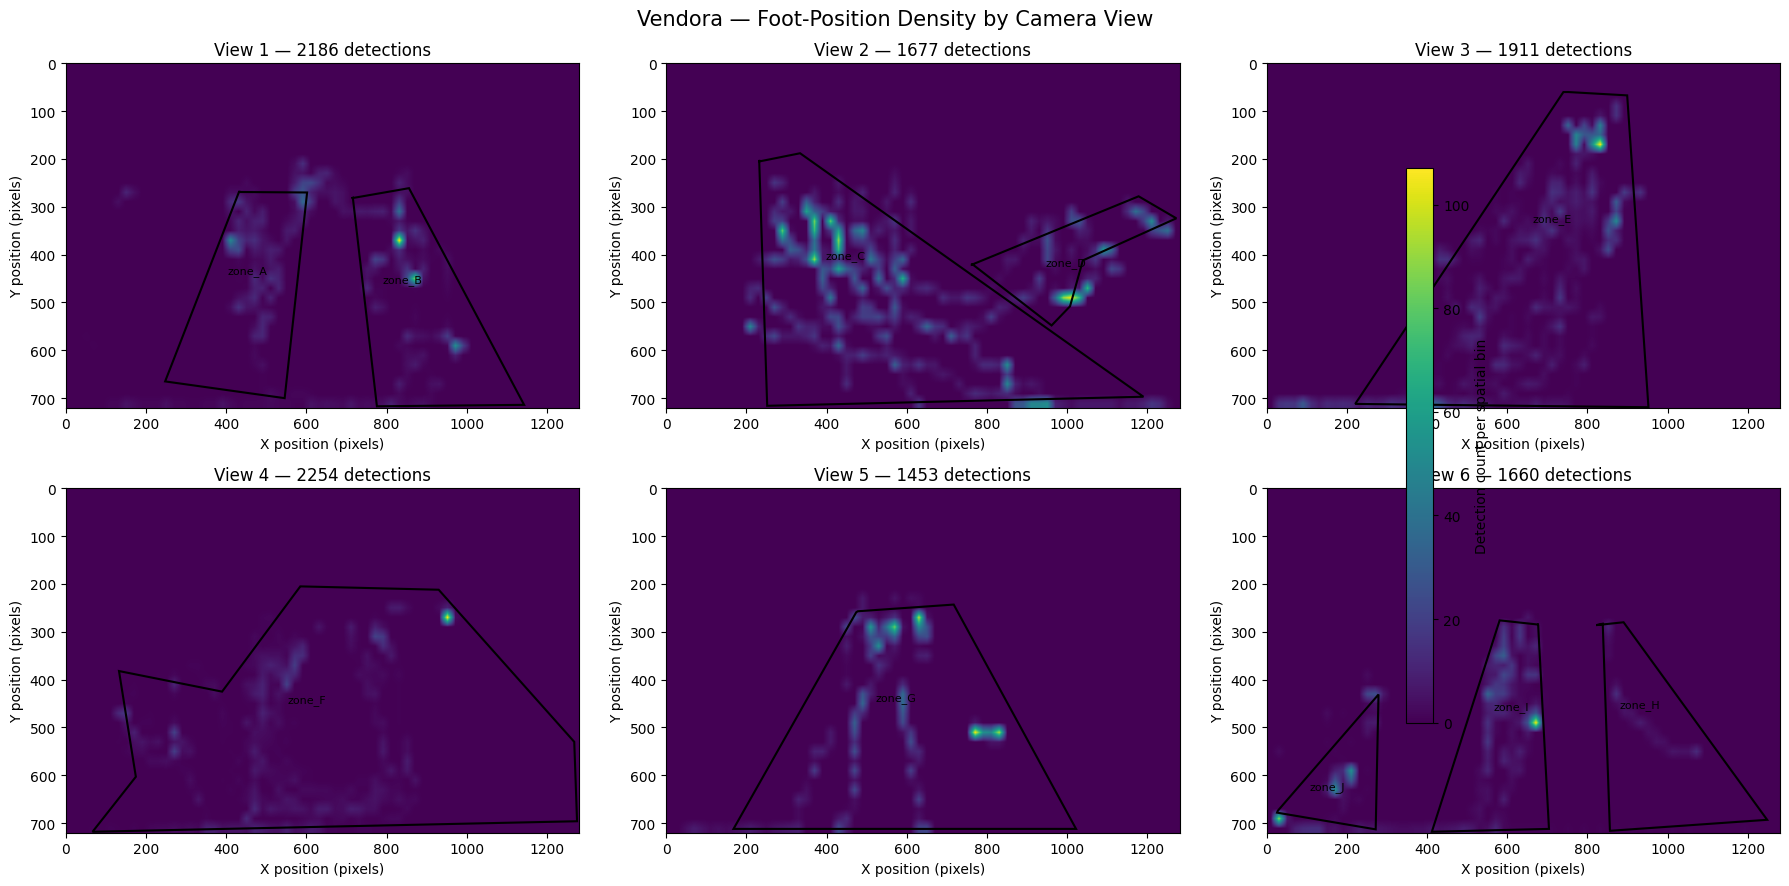

,view_id,detections,occupied_heatmap_bins,peak_bin_detections
0,1,2186,262,130
1,2,1677,340,33
2,3,1911,324,87
3,4,2254,352,185
4,5,1453,127,80
5,6,1660,216,107


Saved heatmaps and summary to: /content/vendora_analytics_outputs


In [7]:
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

tracks_path = Path(
    "/content/drive/MyDrive/vendora_botsort_reid_rebuild/"
    "all_views_tracks_manual_corrections_v5.csv"
)
zones_path = Path("/content/combined_cctv__2__zones.json")
output_dir = Path("/content/vendora_analytics_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

tracks = pd.read_csv(tracks_path)
with open(zones_path, "r") as f:
    zone_data = json.load(f)

W = int(zone_data["video_resolution"]["width"])
H = int(zone_data["video_resolution"]["height"])

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
heatmap_rows = []

for view, ax in zip(zone_data["views"], axes.flat):
    view_id = int(view["view_id"])
    data = tracks[tracks["view_id"] == view_id]

    # Pixel-level foot-position frequency, displayed as a smoothed-looking
    # coarse grid rather than pretending each pixel is independently meaningful.
    heat, xedges, yedges = np.histogram2d(
        data["foot_x"],
        data["foot_y"],
        bins=[64, 36],
        range=[[0, W], [0, H]]
    )

    image = ax.imshow(
        heat.T,
        origin="upper",
        extent=[0, W, H, 0],
        aspect="auto",
        interpolation="bilinear"
    )

    for zone in view.get("zones", []):
        points = np.array(zone["points"], dtype=np.int32)
        if len(points) > 1 and np.array_equal(points[0], points[-1]):
            points = points[:-1]

        polygon = plt.Polygon(
            points,
            closed=True,
            fill=False,
            linewidth=1.5
        )
        ax.add_patch(polygon)

        # Label near the polygon's average point
        center_x, center_y = points.mean(axis=0)
        ax.text(center_x, center_y, zone["name"],
                fontsize=8, ha="center", va="center")

    ax.set_title(f"View {view_id} — {len(data)} detections")
    ax.set_xlim(0, W)
    ax.set_ylim(H, 0)
    ax.set_xlabel("X position (pixels)")
    ax.set_ylabel("Y position (pixels)")

    heatmap_rows.append({
        "view_id": view_id,
        "detections": len(data),
        "occupied_heatmap_bins": int((heat > 0).sum()),
        "peak_bin_detections": int(heat.max()) if heat.size else 0
    })

fig.colorbar(image, ax=list(axes.flat), label="Detection count per spatial bin",
             shrink=0.8)
fig.suptitle("Vendora — Foot-Position Density by Camera View", fontsize=15)
fig.tight_layout()
fig.savefig(output_dir / "six_view_foot_traffic_heatmaps.png",
            dpi=160, bbox_inches="tight")
plt.show()

heatmap_summary = pd.DataFrame(heatmap_rows)
display(heatmap_summary)

heatmap_summary.to_csv(
    output_dir / "heatmap_summary.csv", index=False
)

print("Saved heatmaps and summary to:", output_dir)

In [8]:
import json
import numpy as np
import pandas as pd
from pathlib import Path

project_dir = Path("/content/drive/MyDrive/vendora_botsort_reid_rebuild")
tracks = pd.read_csv(project_dir / "all_views_tracks_manual_corrections_v5.csv")

with open("/content/combined_cctv__2__zones.json", "r") as f:
    zone_data = json.load(f)

FPS = float(zone_data["fps"])
output_dir = Path("/content/vendora_analytics_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Calculate movement only between consecutive observations of the same
# corrected track in the same view. Ignore long gaps.
track_data = tracks.sort_values(
    ["view_id", "corrected_track_id", "frame_index"]
).copy()

track_data["previous_frame"] = track_data.groupby(
    ["view_id", "corrected_track_id"]
)["frame_index"].shift()

track_data["previous_x"] = track_data.groupby(
    ["view_id", "corrected_track_id"]
)["foot_x"].shift()

track_data["previous_y"] = track_data.groupby(
    ["view_id", "corrected_track_id"]
)["foot_y"].shift()

track_data["frame_gap"] = (
    track_data["frame_index"] - track_data["previous_frame"]
)

track_data["pixel_distance"] = np.hypot(
    track_data["foot_x"] - track_data["previous_x"],
    track_data["foot_y"] - track_data["previous_y"]
)

# Pixel speed is not physical walking speed; camera calibration is unavailable.
valid = (
    (track_data["frame_gap"] > 0) &
    (track_data["frame_gap"] <= 3)
)

track_data["pixel_speed_per_sec"] = np.where(
    valid,
    track_data["pixel_distance"] * FPS / track_data["frame_gap"],
    np.nan
)

# Per-frame occupancy and speed summaries.
frame_stats = track_data.groupby(
    ["view_id", "frame_index"]
).agg(
    people_observed=("corrected_track_id", "nunique"),
    median_pixel_speed=("pixel_speed_per_sec", "median")
).reset_index()

occupancy_summary = frame_stats.groupby("view_id").agg(
    mean_people_per_frame=("people_observed", "mean"),
    peak_people_per_frame=("people_observed", "max"),
    frames_with_multiple_people=(
        "people_observed", lambda x: int((x >= 3).sum())
    ),
    median_pixel_speed_per_sec=("median_pixel_speed", "median")
).reset_index()

occupancy_summary["mean_people_per_frame"] = (
    occupancy_summary["mean_people_per_frame"].round(2)
)
occupancy_summary["median_pixel_speed_per_sec"] = (
    occupancy_summary["median_pixel_speed_per_sec"].round(2)
)

print("VIEW-LEVEL OCCUPANCY AND MOVEMENT")
display(occupancy_summary)

# Zone-level presence per frame, useful for comparing busy and quiet zones.
zone_presence_rows = []

for view in zone_data["views"]:
    view_id = int(view["view_id"])
    view_tracks = tracks[tracks["view_id"] == view_id]

    for zone in view.get("zones", []):
        pts = np.asarray(zone["points"], dtype=np.int32).reshape((-1, 1, 2))

        inside = view_tracks.apply(
            lambda r: cv2.pointPolygonTest(
                pts, (float(r["foot_x"]), float(r["foot_y"])), False
            ) >= 0,
            axis=1
        )

        z = view_tracks.loc[inside]
        people_by_frame = z.groupby("frame_index")[
            "corrected_track_id"
        ].nunique()

        # Include frames with zero people in the zone.
        start_frame = int(round(float(view["start_sec"]) * FPS))
        end_frame = int(round(float(view["end_sec"]) * FPS))
        all_frames = pd.RangeIndex(start_frame, end_frame)

        people_by_frame = people_by_frame.reindex(
            all_frames, fill_value=0
        )

        zone_presence_rows.append({
            "view_id": view_id,
            "zone_name": zone["name"],
            "zone_type": zone.get("type", "unknown"),
            "mean_people_per_frame": round(float(people_by_frame.mean()), 3),
            "peak_people_in_frame": int(people_by_frame.max()),
            "frames_with_anyone": int((people_by_frame > 0).sum()),
            "frames_with_3plus_people": int((people_by_frame >= 3).sum()),
            "observation_window_sec": round(len(all_frames) / FPS, 2)
        })

zone_presence = pd.DataFrame(zone_presence_rows)

print("\nZONE-LEVEL PRESENCE")
display(zone_presence)

occupancy_summary.to_csv(
    output_dir / "view_occupancy_movement_summary.csv", index=False
)
zone_presence.to_csv(
    output_dir / "zone_occupancy_summary.csv", index=False
)

print("\nSaved occupancy and movement outputs to:", output_dir)

VIEW-LEVEL OCCUPANCY AND MOVEMENT


,view_id,mean_people_per_frame,peak_people_per_frame,frames_with_multiple_people,median_pixel_speed_per_sec
0,1,9.11,12,240,48.11
1,2,6.99,10,240,82.16
2,3,7.96,12,240,101.07
3,4,9.39,13,240,76.06
4,5,6.05,9,240,31.34
5,6,6.92,10,240,74.32



ZONE-LEVEL PRESENCE


,view_id,zone_name,zone_type,mean_people_per_frame,peak_people_in_frame,frames_with_anyone,frames_with_3plus_people,observation_window_sec
0,1,zone_A,shelf,3.337,6,240,215,10.0
1,1,zone_B,shelf,3.837,6,240,240,10.0
2,2,zone_C,shelf,4.812,8,240,226,10.0
3,2,zone_D,shelf,0.846,3,130,19,10.0
4,3,zone_E,shelf,6.379,10,240,240,10.0
5,4,zone_F,general,8.229,12,240,240,10.0
6,5,zone_G,shelf,5.550,8,240,226,10.0
7,6,zone_H,shelf,0.504,2,99,0,10.0
8,6,zone_I,shelf,3.913,6,240,235,10.0
9,6,zone_J,shelf,1.113,3,222,3,10.0



Saved occupancy and movement outputs to: /content/vendora_analytics_outputs


In [9]:
import pandas as pd
from pathlib import Path

output_dir = Path("/content/vendora_analytics_outputs")

flags = zone_presence.copy()

# Normalize activity against each zone's 10-second observation window.
flags["presence_ratio"] = (
    flags["frames_with_anyone"] /
    (flags["observation_window_sec"] * FPS)
)

flags["crowded_frame_ratio"] = (
    flags["frames_with_3plus_people"] /
    (flags["observation_window_sec"] * FPS)
)

# Relative thresholds across the annotated zones.
high_occupancy_threshold = flags["mean_people_per_frame"].quantile(0.75)
low_occupancy_threshold = flags["mean_people_per_frame"].quantile(0.25)

def classify_zone(row):
    high_occupancy = (
        row["mean_people_per_frame"] >= high_occupancy_threshold
    )
    repeated_crowding = row["crowded_frame_ratio"] >= 0.75

    low_activity = (
        row["mean_people_per_frame"] <= low_occupancy_threshold
        and row["presence_ratio"] <= 0.75
    )

    if high_occupancy and repeated_crowding:
        return "Bottleneck candidate — review video"
    elif low_activity:
        return "Low-activity candidate — review video"
    else:
        return "No preliminary flag"

flags["preliminary_flag"] = flags.apply(classify_zone, axis=1)

print("Rule thresholds:")
print(f"High occupancy: >= {high_occupancy_threshold:.3f} people/frame")
print(f"Low occupancy: <= {low_occupancy_threshold:.3f} people/frame")
print("\nPRELIMINARY ZONE FLAGS")

display(flags[[
    "view_id",
    "zone_name",
    "mean_people_per_frame",
    "peak_people_in_frame",
    "presence_ratio",
    "crowded_frame_ratio",
    "preliminary_flag"
]])

flags.to_csv(
    output_dir / "preliminary_zone_flags.csv",
    index=False
)

print("\nSaved to:", output_dir / "preliminary_zone_flags.csv")

Rule thresholds:
High occupancy: >= 5.365 people/frame
Low occupancy: <= 1.669 people/frame

PRELIMINARY ZONE FLAGS


,view_id,zone_name,mean_people_per_frame,peak_people_in_frame,presence_ratio,crowded_frame_ratio,preliminary_flag
0,1,zone_A,3.337,6,1.000000,0.895833,No preliminary flag
1,1,zone_B,3.837,6,1.000000,1.000000,No preliminary flag
2,2,zone_C,4.812,8,1.000000,0.941667,No preliminary flag
3,2,zone_D,0.846,3,0.541667,0.079167,Low-activity candidate — review video
4,3,zone_E,6.379,10,1.000000,1.000000,Bottleneck candidate — review video
5,4,zone_F,8.229,12,1.000000,1.000000,Bottleneck candidate — review video
6,5,zone_G,5.550,8,1.000000,0.941667,Bottleneck candidate — review video
7,6,zone_H,0.504,2,0.412500,0.000000,Low-activity candidate — review video
8,6,zone_I,3.913,6,1.000000,0.979167,No preliminary flag
9,6,zone_J,1.113,3,0.925000,0.012500,No preliminary flag



Saved to: /content/vendora_analytics_outputs/preliminary_zone_flags.csv


In [12]:
from pathlib import Path
import zipfile

output_dir = Path("/content/vendora_analytics_outputs")
zip_path = Path("/content/vendora_submission_outputs.zip")

files_to_include = [
    "README.md",
    "requirements.txt",
    "zone_dwell_summary.csv",
    "zone_visits.csv",
    "zone_membership.csv",
    "six_view_foot_traffic_heatmaps.png",
    "heatmap_summary.csv",
    "view_occupancy_movement_summary.csv",
    "zone_occupancy_summary.csv",
    "preliminary_zone_flags.csv",
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for filename in files_to_include:
        path = output_dir / filename
        if path.exists():
            zf.write(path, arcname=filename)
        else:
            print("Missing:", filename)

print("ZIP created:", zip_path)
print("Size:", round(zip_path.stat().st_size / 1024, 1), "KB")

ZIP created: /content/vendora_submission_outputs.zip
Size: 581.4 KB


In [13]:
from google.colab import files
files.download("/content/vendora_submission_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>